# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 6                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = True      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 6 — Гостиничный бизнес
Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»

CSV  : Отели        (справочник субъектов)
XLSX : Бронирования          (события, объём в единицах: ночей)
JSON : Тарифы номеров          (цены, разрез: категория номера)

Объём генерации: субъектов 9, событий 3 000, уровень дефектов ★
Аналитическая задача: Сезонность загрузки и вклад категорий номеров


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,
        "founded_year": rng.integers(1990, 2021, n),
    })

    parents.loc[len(parents)] = parents.iloc[1].tolist()
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)

    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })

    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None
    events.loc[part_text, "volume_units"] = [
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)

    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       10   размер:      0.7 КБ
events.xlsx     строк:    3 000   размер:    112.4 КБ
prices.json     строк:    6 056   размер:    819.0 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений."""
    rows = []
    for col in df.columns:
        s = df[col]
        filled = s.notna() & (s.astype(str).str.strip() != "")

        kinds = sorted({type(v).__name__ for v in s.dropna()})
        rows.append({
            "источник": name,
            "колонка": col,
            "тип": " / ".join(kinds) if kinds else "—",
            "заполнено, %": round(filled.mean() * 100, 2),
            "уникальных": int(s.nunique(dropna=True)),
            "примеры": " | ".join(map(str, s.dropna().unique()[:2])),
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

SRC_E, SRC_EV, SRC_P = list(SOURCES)
DATE_ISO = r"^\d{4}-\d{2}-\d{2}$"
DATE_RU = r"^\d{2}\.\d{2}\.\d{4}$"

def is_blank(s):
    return s.isna() | (s.astype(str).str.strip() == "")

def raw_number(s):
    """Грубое числовое значение для аудита: только «чистые» числа, остальное → NaN."""
    return pd.to_numeric(s, errors="coerce")


for name, df in SOURCES.items():
    for col in df.columns:
        n_blank = int(is_blank(df[col]).sum())
        if n_blank:
            add_issue("Полнота", name, f"пропуски в колонке {col}", n_blank,
                      "оставить пропуском (не 0); строки без цены — в карантин")


for name, df, key in [(SRC_E, raw_entities, "entity_id"), (SRC_EV, raw_events, "event_id"),
                      (SRC_P, raw_prices, "price_id")]:
    n_full = int(df.astype(str).duplicated().sum())
    n_key = int(df[key].duplicated().sum())
    add_issue("Уникальность", name, "полные дубликаты строк", n_full,
              "удалить, оставив первую запись" if n_full else "дефект не обнаружен")
    add_issue("Уникальность", name, f"повторы ключа {key}", n_key,
              "дедупликация по ключу, первая запись" if n_key else "дефект не обнаружен")


dates = raw_events["event_date"].astype(str).str.strip()
add_issue("Согласованность", SRC_EV, "дата в формате ДД.ММ.ГГГГ вместо ГГГГ-ММ-ДД",
          dates.str.match(DATE_RU).sum(), "разобрать оба формата, хранить ГГГГ-ММ-ДД")
add_issue("Согласованность", SRC_EV, "дата не распознана ни в одном формате",
          (~dates.str.match(DATE_ISO) & ~dates.str.match(DATE_RU) & raw_events["event_date"].notna()).sum(),
          "в карантин")
vol = raw_events["volume_units"]
add_issue("Согласованность", SRC_EV, "объём записан текстом с пробелами",
          (vol.notna() & (vol.astype(str) != vol.astype(str).str.strip())).sum(),
          "убрать пробелы, привести к числу")
price_is_text = raw_prices["unit_price"].map(lambda v: isinstance(v, str))
add_issue("Согласованность", SRC_P, "цена строкой с валютой и пробелом-разделителем",
          price_is_text.sum(), "очистить строку, привести к числу")
names = raw_entities["entity_name"].astype(str)
add_issue("Согласованность", SRC_E, "имя с лишними пробелами или в верхнем регистре",
          ((names != names.str.strip()) | (names == names.str.upper())).sum(),
          "убрать пробелы, привести регистр к виду справочника")


price_num = raw_number(raw_prices["unit_price"])
vol_num = raw_number(raw_events["volume_units"])
add_issue("Валидность", SRC_P, "цена ≤ 0", (price_num <= 0).sum(),
          "в карантин" if (price_num <= 0).any() else "дефект не обнаружен")
add_issue("Валидность", SRC_EV, "объём ≤ 0", (vol_num <= 0).sum(),
          "в карантин" if (vol_num <= 0).any() else "дефект не обнаружен")


known_entities = set(raw_entities["entity_id"])
known_events = set(raw_events["event_id"])
orph_ev = ~raw_events["entity_id"].isin(known_entities)
orph_p = ~raw_prices["event_id"].isin(known_events)
add_issue("Целостность", SRC_EV, "entity_id нет в справочнике", orph_ev.sum(),
          "в карантин quarantine_fk" if orph_ev.any() else "дефект не обнаружен")
add_issue("Целостность", SRC_P, "event_id нет среди событий", orph_p.sum(),
          "в карантин quarantine_fk" if orph_p.any() else "дефект не обнаружен")
add_issue("Целостность", SRC_E, "субъект без единого события",
          (~raw_entities["entity_id"].isin(set(raw_events["entity_id"]))).sum(),
          "оставить: справочник может быть шире фактов")
add_issue("Целостность", SRC_EV, "событие без единой цены",
          (~raw_events["event_id"].isin(set(raw_prices["event_id"]))).sum(),
          "не войдёт в выручку — отметить в выводах")


OUTLIER_K = 3.0
p_aud = raw_prices.assign(price=price_num).dropna(subset=["price"])
p_aud = p_aud[p_aud["price"] > 0]
n_out = 0
for _, g in p_aud.groupby("price_class"):
    q1, q3 = g["price"].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out += int(((g["price"] < q1 - OUTLIER_K * iqr) | (g["price"] > q3 + OUTLIER_K * iqr)).sum())
add_issue("Точность", SRC_P, f"выбросы цены по правилу {OUTLIER_K:g}×IQR внутри класса", n_out,
          "проверить у владельца источника, не удалять" if n_out else "дефект не обнаружен")

issues_df = pd.DataFrame(issues)
found = issues_df[issues_df["строк"] > 0]
print(f"Проверок выполнено: {len(issues_df)} | проблем найдено: {len(found)} "
      f"| измерений с проблемами: {found['измерение'].nunique()} из 6")
display(issues_df.sort_values(["строк"], ascending=False).reset_index(drop=True))

# ------------------------------------------------------------------ TODO 3.3
ev_per_entity = raw_events.drop_duplicates("event_id").groupby("entity_id").size()
p_per_event = raw_prices.drop_duplicates("price_id").groupby("event_id").size()
cardinality = pd.DataFrame({
    "связь": [f"{CFG['parent']} → {CFG['event']}", f"{CFG['event']} → {CFG['price']}"],
    "тип": ["1 : N", "1 : N"],
    "потомков в среднем": [ev_per_entity.mean(), p_per_event.mean()],
    "максимум": [ev_per_entity.max(), p_per_event.max()],
})
display(cardinality)
FANOUT_EXPECTED = p_per_event.mean()
print(textwrap.fill(
    f"Ответ: у одного события в среднем {FANOUT_EXPECTED:.2f} ценовых строк (максимум {p_per_event.max()}). "
    f"При наивном JOIN трёх таблиц строка события повторится столько раз, сколько у неё цен, "
    f"поэтому SUM(объём) вырастет примерно в {FANOUT_EXPECTED:.2f} раза, а выручка будет завышена "
    f"так же. Связь «{CFG['parent']} → {CFG['event']}» fan-out не даёт: субъект — родитель, "
    f"у каждого события ровно один субъект.", 104))

,источник,колонка,тип,"заполнено, %",уникальных,примеры
0,CSV · Отели,entity_id,str,100.00,9,E001 | E002
1,CSV · Отели,entity_name,str,100.00,9,Отели «Ростов-на-Дону» | Отели «Казань»
2,CSV · Отели,region,str,100.00,9,Ростов-на-Дону | Казань
3,CSV · Отели,founded_year,str,100.00,8,1998 | 2010
4,XLSX · Бронирования,event_id,str,100.00,3000,EV000001 | EV000002
5,XLSX · Бронирования,entity_id,str,100.00,9,E001 | E003
6,XLSX · Бронирования,event_date,str,100.00,375,2025-12-22 | 2025-09-30
7,XLSX · Бронирования,route,str,100.00,144,Уфа — Омск | Екатеринбург — Екатеринбург
8,XLSX · Бронирования,volume_units,str,99.67,365,379 | 269
9,XLSX · Бронирования,asset_type,str,100.00,4,Тип B | Тип C


Проверок выполнено: 20 | проблем найдено: 8 | измерений с проблемами: 3 из 6


,измерение,источник,проблема,строк,решение
0,Полнота,JSON · Тарифы номеров,пропуски в колонке unit_price,13,оставить пропуском (не 0); строки без цены — в...
1,Согласованность,JSON · Тарифы номеров,цена строкой с валютой и пробелом-разделителем,13,"очистить строку, привести к числу"
2,Согласованность,XLSX · Бронирования,дата в формате ДД.ММ.ГГГГ вместо ГГГГ-ММ-ДД,10,"разобрать оба формата, хранить ГГГГ-ММ-ДД"
3,Полнота,XLSX · Бронирования,пропуски в колонке volume_units,10,оставить пропуском (не 0); строки без цены — в...
4,Согласованность,XLSX · Бронирования,объём записан текстом с пробелами,10,"убрать пробелы, привести к числу"
5,Уникальность,CSV · Отели,полные дубликаты строк,1,"удалить, оставив первую запись"
6,Уникальность,CSV · Отели,повторы ключа entity_id,1,"дедупликация по ключу, первая запись"
7,Согласованность,CSV · Отели,имя с лишними пробелами или в верхнем регистре,1,"убрать пробелы, привести регистр к виду справо..."
8,Уникальность,JSON · Тарифы номеров,повторы ключа price_id,0,дефект не обнаружен
9,Уникальность,JSON · Тарифы номеров,полные дубликаты строк,0,дефект не обнаружен


,связь,тип,потомков в среднем,максимум
0,Отели → Бронирования,1 : N,333.33,517
1,Бронирования → Тарифы номеров,1 : N,2.02,3


Ответ: у одного события в среднем 2.02 ценовых строк (максимум 3). При наивном JOIN трёх таблиц строка
события повторится столько раз, сколько у неё цен, поэтому SUM(объём) вырастет примерно в 2.02 раза, а
выручка будет завышена так же. Связь «Отели → Бронирования» fan-out не даёт: субъект — родитель, у
каждого события ровно один субъект.


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def _one_number(v):
    """Одно значение → float или NaN."""
    if v is None or (isinstance(v, float) and math.isnan(v)):
        return np.nan
    if isinstance(v, (int, float, np.integer, np.floating)):
        return float(v)
    s = re.sub(r"[^\d,.\-]", "", str(v))
    if not re.search(r"\d", s):
        return np.nan
    if "," in s and "." in s:
        s = s.replace(".", "").replace(",", ".") if s.rfind(",") > s.rfind(".") else s.replace(",", "")
    elif "," in s:
        s = s.replace(",", "") if re.fullmatch(r"-?\d{1,3}(,\d{3})+", s) else s.replace(",", ".")
    return s

def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN"""
    return pd.to_numeric(series.map(_one_number), errors="coerce").astype(float)

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    s = series.astype("object").where(series.notna(), None).map(lambda v: str(v).strip() if v else v)
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    ru = pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
    return iso.fillna(ru)

# мини-тесты функций очистки
_t = to_number(pd.Series(["8 500,00 ₽", "180 ", None, "1,234.56", 4200.5, "8 500.00 ₽"]))
assert _t.iloc[0] == 8500.0 and _t.iloc[1] == 180.0 and pd.isna(_t.iloc[2])
assert _t.iloc[3] == 1234.56 and _t.iloc[4] == 4200.5 and _t.iloc[5] == 8500.0
_d = to_date(pd.Series(["2025-03-17", "17.03.2025", "мусор", None]))
assert _d.iloc[0] == _d.iloc[1] == pd.Timestamp("2025-03-17") and _d.iloc[2:].isna().all()
print("Функции to_number и to_date прошли проверку")

# ------------------------------------------------------------------ TODO 4.3
# ---------- 1. Справочник субъектов
entities = raw_entities.copy()
n0 = len(entities)
entities = entities.drop_duplicates(subset="entity_id", keep="first").reset_index(drop=True)
log_step("Справочник: дедупликация по entity_id", n0, len(entities), "удалены повторы ключа, оставлена первая запись")

def clean_name(name):
    """Лишние пробелы → один; «КРИЧАЩИЙ» регистр → как в остальном справочнике: «Отели «Казань»»."""
    name = re.sub(r"\s+", " ", str(name)).strip()
    if name != name.upper():
        return name
    head, quote, city = name.partition("«")
    city = city.rstrip("»").lower()
    city = "-".join(p if p in ("на", "над", "под") else p.capitalize() for p in city.split("-"))
    return head.capitalize() + (f"«{city}»" if quote else "")

names_before = entities["entity_name"].copy()
entities["entity_name"] = entities["entity_name"].map(clean_name)
entities["region"] = entities["region"].map(lambda v: re.sub(r"\s+", " ", v).strip() if isinstance(v, str) else v)
entities["founded_year"] = to_number(entities["founded_year"]).astype("Int64")
log_step("Справочник: нормализация имён", len(entities), len(entities),
         f"изменено имён: {(names_before != entities['entity_name']).sum()} (пробелы, регистр); строки не удалялись")

# ---------- 2. События
events = raw_events.copy()
n0 = len(events)
events = events.drop_duplicates(subset="event_id", keep="first").reset_index(drop=True)
log_step("События: дедупликация по event_id", n0, len(events), "удалены повторы ключа")

events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])
log_step("События: разбор дат и объёма", len(events), len(events),
         f"дат не распознано: {events['event_date'].isna().sum()}; "
         f"объём-пропусков: {events['volume_units'].isna().sum()} — остались NaN, не 0")

fk_bad = ~events["entity_id"].isin(set(entities["entity_id"]))
quarantine_fk = events[fk_bad].assign(причина="entity_id нет в справочнике")
events = events[~fk_bad]
log_step("События: ссылочная целостность → карантин", len(events) + fk_bad.sum(), len(events),
         f"в quarantine_fk: {fk_bad.sum()}")

bad_event = events["event_date"].isna() | (events["volume_units"] <= 0)
quarantine_event = events[bad_event].assign(причина="дата не распознана или объём ≤ 0")
events_valid = events[~bad_event].reset_index(drop=True)
log_step("События: непригодные значения → карантин", len(events), len(events_valid),
         f"в quarantine_event: {bad_event.sum()} (пропуск объёма не считается непригодным — он остаётся NaN)")

# ---------- 3. Цены
prices = raw_prices.copy()
n0 = len(prices)
prices = prices.drop_duplicates(subset="price_id", keep="first").reset_index(drop=True)
log_step("Цены: дедупликация по price_id", n0, len(prices), "удалены повторы ключа")

n_text = prices["unit_price"].map(lambda v: isinstance(v, str)).sum()
prices["unit_price"] = to_number(prices["unit_price"])
log_step("Цены: приведение к числу", len(prices), len(prices),
         f"строк с валютой разобрано: {n_text}; строки не удалялись")

fk_p = ~prices["event_id"].isin(set(events_valid["event_id"]))
quarantine_fk = pd.concat([quarantine_fk,
                           prices[fk_p].assign(причина="event_id нет среди валидных событий")],
                          ignore_index=True)
prices = prices[~fk_p]
log_step("Цены: ссылочная целостность → карантин", len(prices) + fk_p.sum(), len(prices),
         f"в quarantine_fk: {fk_p.sum()}")

bad_price = prices["unit_price"].isna() | (prices["unit_price"] <= 0)
quarantine_price = prices[bad_price].assign(
    причина=np.where(prices.loc[bad_price, "unit_price"].isna(), "цена отсутствует", "цена ≤ 0"))
prices_valid = prices[~bad_price].reset_index(drop=True)
log_step("Цены: пропуски и неположительные → карантин", len(prices), len(prices_valid),
         f"в quarantine_price: {bad_price.sum()} — без цены строка не может войти в среднюю цену")

clean_log = pd.DataFrame(CLEAN_LOG)
display(clean_log)

total_raw = len(raw_events) + len(raw_prices)
total_q = len(quarantine_fk) + len(quarantine_event) + len(quarantine_price)
no_price = (~events_valid["event_id"].isin(set(prices_valid["event_id"]))).sum()
print(f"Итог: субъектов {len(entities)}, событий {nf(len(events_valid))}, цен {nf(len(prices_valid))}")
print(f"Карантин: FK {len(quarantine_fk)}, события {len(quarantine_event)}, цены {len(quarantine_price)} "
      f"→ {total_q / total_raw:.2%} строк событий и цен (порог для разговора с источником — 5 %)")
print(f"Событий с пропуском объёма (NaN): {events_valid['volume_units'].isna().sum()}; "
      f"событий без единой валидной цены: {no_price} — они не дадут выручки")

Функции to_number и to_date прошли проверку


,шаг,было строк,стало строк,изменено,комментарий
0,Справочник: дедупликация по entity_id,10,9,1,"удалены повторы ключа, оставлена первая запись"
1,Справочник: нормализация имён,9,9,0,"изменено имён: 1 (пробелы, регистр); строки не..."
2,События: дедупликация по event_id,3000,3000,0,удалены повторы ключа
3,События: разбор дат и объёма,3000,3000,0,дат не распознано: 0; объём-пропусков: 10 — ос...
4,События: ссылочная целостность → карантин,3000,3000,0,в quarantine_fk: 0
5,События: непригодные значения → карантин,3000,3000,0,в quarantine_event: 0 (пропуск объёма не счита...
6,Цены: дедупликация по price_id,6056,6056,0,удалены повторы ключа
7,Цены: приведение к числу,6056,6056,0,строк с валютой разобрано: 13; строки не удаля...
8,Цены: ссылочная целостность → карантин,6056,6056,0,в quarantine_fk: 0
9,Цены: пропуски и неположительные → карантин,6056,6043,13,в quarantine_price: 13 — без цены строка не мо...


Итог: субъектов 9, событий 3 000, цен 6 043
Карантин: FK 0, события 0, цены 13 → 0.14% строк событий и цен (порог для разговора с источником — 5 %)
Событий с пропуском объёма (NaN): 10; событий без единой валидной цены: 2 — они не дадут выручки


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [6]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")

# ------------------------------------------------------------------ TODO 5.1
SCHEMA = """
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY,
    entity_name  TEXT NOT NULL,
    region       TEXT,
    founded_year INTEGER CHECK (founded_year BETWEEN 1800 AND 2100)
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id),
    event_date   TEXT NOT NULL CHECK (event_date GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'),
    route        TEXT,
    volume_units INTEGER CHECK (volume_units > 0),         -- NULL допустим: пропуск остаётся пропуском
    asset_type   TEXT
);
CREATE TABLE prices (
    price_id     TEXT PRIMARY KEY,
    event_id     TEXT NOT NULL REFERENCES events(event_id),
    unit_price   REAL NOT NULL CHECK (unit_price > 0),
    price_class  TEXT NOT NULL
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
"""
conn.executescript(SCHEMA)
conn.execute("PRAGMA foreign_keys = ON;")
print("PRAGMA foreign_keys =", conn.execute("PRAGMA foreign_keys").fetchone()[0])

# ------------------------------------------------------------------ TODO 5.2

events_out = events_valid.assign(event_date=events_valid["event_date"].dt.strftime("%Y-%m-%d"))
events_out = events_out[["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]]
prices_out = prices_valid[["price_id", "event_id", "unit_price", "price_class"]]


entities.to_sql("entities", conn, if_exists="append", index=False)
events_out.to_sql("events", conn, if_exists="append", index=False)
prices_out.to_sql("prices", conn, if_exists="append", index=False)
conn.commit()

loaded = pd.DataFrame(
    [(t, conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0], n)
     for t, n in [("entities", len(entities)), ("events", len(events_out)), ("prices", len(prices_out))]],
    columns=["таблица", "строк в базе", "строк после очистки"])
loaded["совпадает"] = loaded["строк в базе"] == loaded["строк после очистки"]
display(loaded)
print("Нарушений внешних ключей:", len(conn.execute("PRAGMA foreign_key_check").fetchall()))

# ------------------------------------------------------------------ TODO 5.3
naive_sql = """
SELECT e.entity_id, e.entity_name,
       SUM(ev.volume_units)                AS volume_naive,
       SUM(ev.volume_units * p.unit_price) AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id  = ev.event_id          -- 1 : N — строка события размножается
GROUP BY e.entity_id, e.entity_name
"""
correct_sql = """
WITH price_per_event AS (                              -- сначала свёртка: одна строка на событие
    SELECT event_id, AVG(unit_price) AS avg_price, COUNT(*) AS n_prices
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id, e.entity_name,
       COUNT(ev.event_id)                   AS events_cnt,
       SUM(ev.volume_units)                 AS volume,
       SUM(ev.volume_units * pe.avg_price)  AS revenue
FROM entities e
JOIN events ev          ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name
ORDER BY revenue DESC
"""
revenue_naive = pd.read_sql(naive_sql, conn)
revenue_sql = pd.read_sql(correct_sql, conn)

compare = revenue_sql.merge(revenue_naive, on=["entity_id", "entity_name"])
compare["завышение выручки, раз"] = compare["revenue_naive"] / compare["revenue"]
compare["завышение объёма, раз"] = compare["volume_naive"] / compare["volume"]
overstate = revenue_naive["revenue_naive"].sum() / revenue_sql["revenue"].sum()
overstate_volume = revenue_naive["volume_naive"].sum() / revenue_sql["volume"].sum()
display(compare[["entity_name", "events_cnt", "volume", "volume_naive", "revenue", "revenue_naive",
                 "завышение объёма, раз", "завышение выручки, раз"]])
print(f"Итог: корректная выручка {nf(revenue_sql['revenue'].sum())} ₽, наивная "
      f"{nf(revenue_naive['revenue_naive'].sum())} ₽ → завышение в {overstate:.3f} раза "
      f"(объём — в {overstate_volume:.3f} раза; ценовых строк на событие в среднем {FANOUT_EXPECTED:.3f})")
print(textwrap.fill(
    f"Откуда завышение: у события n ценовых строк (1–3 {CFG['cls']}). JOIN «в лоб» повторяет строку "
    f"события n раз, поэтому объём ({CFG['unit']}) суммируется n раз, а выручка события получается "
    f"объём × сумма цен = n × (объём × средняя цена), то есть тоже в n раз больше. Итоговый коэффициент — "
    f"это среднее n по событиям, взвешенное выручкой, поэтому он близок к среднему числу цен на событие, "
    f"но не равен ему точно. Корректный путь — свернуть цены до события (CTE с AVG), потом соединять.", 104))

# ------------------------------------------------------------------ TODO 5.4
avg_price = (prices_valid.groupby("event_id", as_index=False)
             .agg(avg_price=("unit_price", "mean"), n_prices=("unit_price", "size")))
consolidated = (events_valid.merge(avg_price, on="event_id", how="inner")
                .merge(entities[["entity_id", "entity_name", "region"]], on="entity_id", how="inner"))
consolidated["revenue"] = consolidated["volume_units"] * consolidated["avg_price"]
revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"), volume=("volume_units", "sum"),
                   revenue=("revenue", "sum"))
              .sort_values("revenue", ascending=False, ignore_index=True))

check_df = revenue_sql.merge(revenue_pd, on="entity_id", suffixes=("_sql", "_pd"))
check_df["расхождение, ₽"] = (check_df["revenue_sql"] - check_df["revenue_pd"]).abs()
delta = check_df["расхождение, ₽"].max()
display(check_df[["entity_name_sql", "events_cnt_sql", "events_cnt_pd", "revenue_sql", "revenue_pd",
                  "расхождение, ₽"]])
print(f"Максимальное расхождение SQL и pandas: {delta:.6f} ₽ "
      f"({'на уровне округления — расчёты сходятся' if delta < 1 else 'РАСХОЖДЕНИЕ — искать причину'})")

PRAGMA foreign_keys = 1


,таблица,строк в базе,строк после очистки,совпадает
0,entities,9,9,True
1,events,3000,3000,True
2,prices,6043,6043,True


Нарушений внешних ключей: 0


,entity_name,events_cnt,volume,volume_naive,revenue,revenue_naive,"завышение объёма, раз","завышение выручки, раз"
0,Отели «Ростов-на-Дону»,516,104805,213723,"1,717,099,037.22","3,501,679,073.79",2.04,2.04
1,Отели «Казань»,483,99226,199344,"1,643,499,441.15","3,295,505,778.36",2.01,2.01
2,Отели «Краснодар»,430,89912,184494,"1,567,070,380.88","3,170,240,927.58",2.05,2.02
3,Отели «Екатеринбург»,357,73853,148455,"1,217,943,139.21","2,480,275,853.03",2.01,2.04
4,Отели «Москва»,331,65821,133606,"1,129,675,034.19","2,302,114,388.79",2.03,2.04
5,Отели «Самара»,319,66396,128279,"1,096,210,913.26","2,069,598,299.66",1.93,1.89
6,Отели «Пермь»,247,50968,107942,"878,687,381.42","1,881,817,723.07",2.12,2.14
7,Отели «Новосибирск»,176,36970,75923,"573,602,317.30","1,233,871,162.07",2.05,2.15
8,Отели «Санкт-Петербург»,139,26332,50600,"448,759,302.09","849,053,666.96",1.92,1.89


Итог: корректная выручка 10 272 546 947 ₽, наивная 20 784 156 873 ₽ → завышение в 2.023 раза (объём — в 2.022 раза; ценовых строк на событие в среднем 2.019)
Откуда завышение: у события n ценовых строк (1–3 категория номера). JOIN «в лоб» повторяет строку
события n раз, поэтому объём (ночей) суммируется n раз, а выручка события получается объём × сумма цен =
n × (объём × средняя цена), то есть тоже в n раз больше. Итоговый коэффициент — это среднее n по
событиям, взвешенное выручкой, поэтому он близок к среднему числу цен на событие, но не равен ему точно.
Корректный путь — свернуть цены до события (CTE с AVG), потом соединять.


,entity_name_sql,events_cnt_sql,events_cnt_pd,revenue_sql,revenue_pd,"расхождение, ₽"
0,Отели «Ростов-на-Дону»,516,516,"1,717,099,037.22","1,717,099,037.22",0.00
1,Отели «Казань»,483,483,"1,643,499,441.15","1,643,499,441.15",0.00
2,Отели «Краснодар»,430,430,"1,567,070,380.88","1,567,070,380.88",0.00
3,Отели «Екатеринбург»,357,357,"1,217,943,139.21","1,217,943,139.21",0.00
4,Отели «Москва»,331,331,"1,129,675,034.19","1,129,675,034.19",0.00
5,Отели «Самара»,319,319,"1,096,210,913.26","1,096,210,913.26",0.00
6,Отели «Пермь»,247,247,"878,687,381.42","878,687,381.42",0.00
7,Отели «Новосибирск»,176,176,"573,602,317.30","573,602,317.30",0.00
8,Отели «Санкт-Петербург»,139,139,"448,759,302.09","448,759,302.09",0.00


Максимальное расхождение SQL и pandas: 0.000000 ₽ (на уровне округления — расчёты сходятся)


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

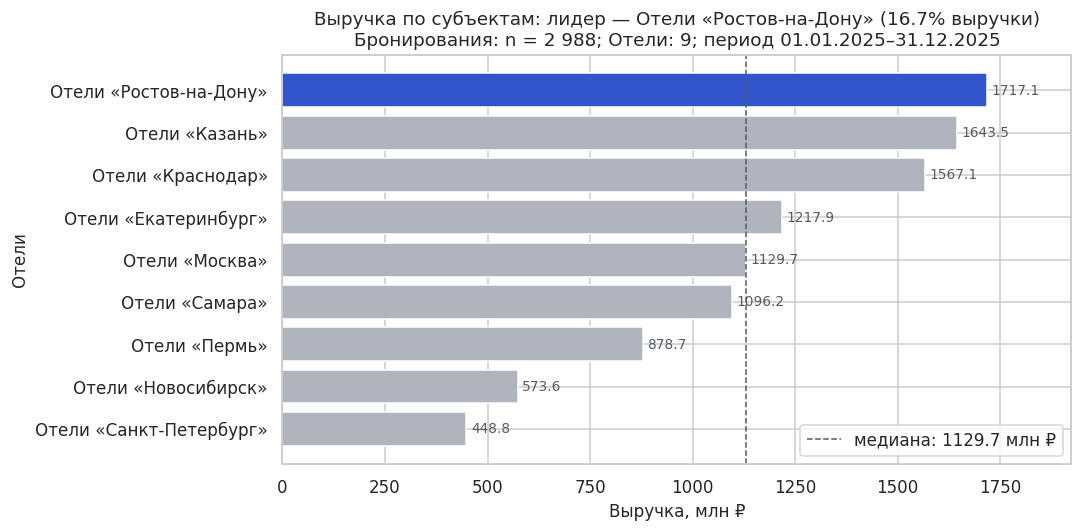

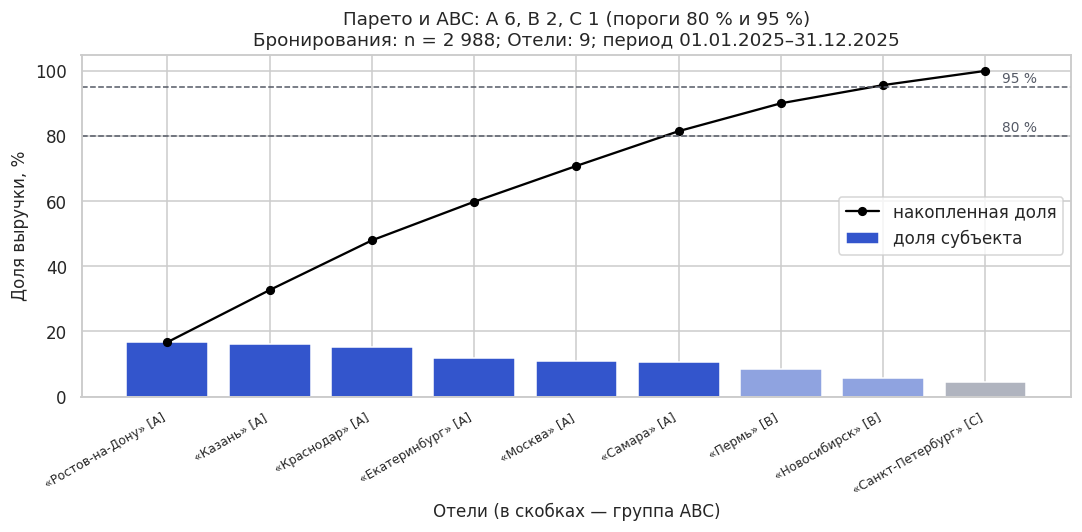

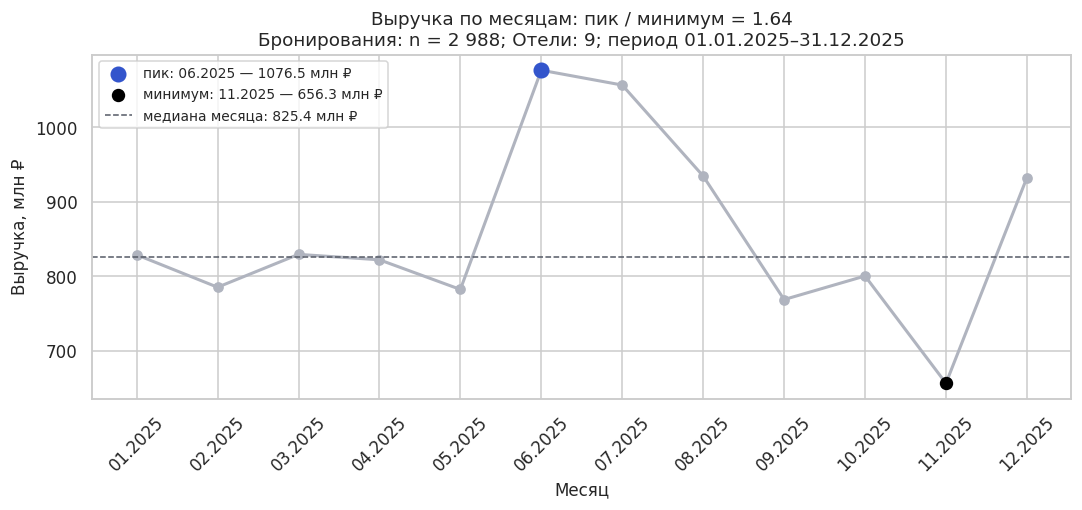

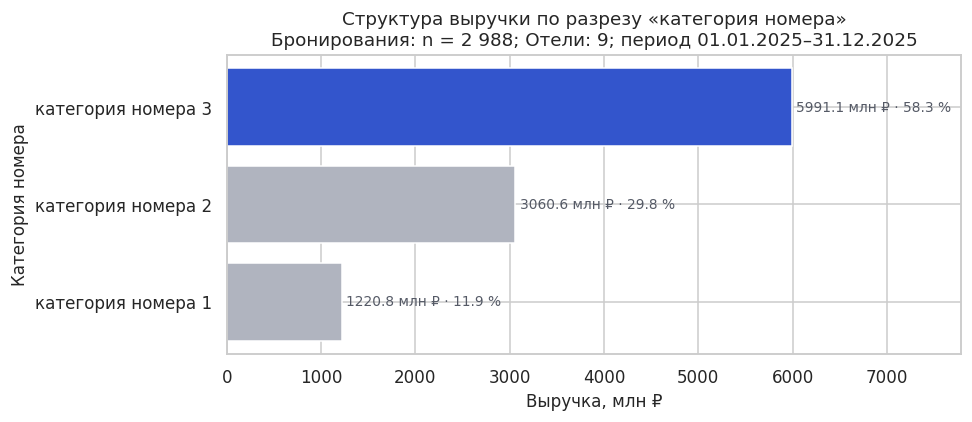

,разрез,"сумма, ₽","отклонение от итога, ₽"
0,по субъектам (SQL),"10,272,546,946.71",0.00
1,по субъектам (pandas),"10,272,546,946.71",0.00
2,по месяцам,"10,272,546,946.71",0.00
3,по разрезу «категория номера»,"10,272,546,946.71",0.00


,бронирования,ночей,"выручка, млн ₽"
месяц,,,
2025-01,270,"50,535.00",828.78
2025-02,240,"46,631.00",785.22
2025-03,250,"47,510.00",829.32
2025-04,259,"48,351.00",822.05
2025-05,255,"46,632.00",782.24
2025-06,247,"59,220.00","1,076.47"
2025-07,257,"61,775.00","1,056.55"
2025-08,249,"59,696.00",934.46
2025-09,251,"46,858.00",768.67


,revenue,price_rows,avg_price,"доля, %"
price_class,,,,
категория номера 1,"1,220,785,586.37",2052,"5,784.86",11.88
категория номера 2,"3,060,637,326.92",1989,"14,921.20",29.79
категория номера 3,"5,991,124,033.42",2002,"29,976.00",58.32



### Выводы для ЛПР: гостиничный бизнес, вариант 6

**Что посчитано.** Отели: 9; бронирования: 3 000
(в выручку вошли 2 988); строк «Тарифы номеров»: 6 043; период 01.01.2025–31.12.2025.
Итоговая выручка — **10 272.5 млн ₽**
(SQL и pandas совпали, расхождение 0.000000 ₽).

**1. Концентрация.** Лидер — Отели «Ростов-на-Дону»: 16.7% выручки; топ-3 —
48.0 %. В группу A (80 % выручки) входят 6 из 9 субъектов —
выручка распределена довольно ровно, зависимости от одного объекта нет.

**2. Сезонность.** Пик — 06.2025 (1076.5 млн ₽), минимум —
11.2025 (656.3 млн ₽): разрыв
1.64 раза. Летние месяцы (06–08) дают
29.9% годовой выручки при 25% месяцев.

**3. Вклад категорий номеров.** Больше всего приносит «категория номера 3» — 58.3 %
выручки при средней цене 29,976 ₽ за ночь.

**4. Влияние качества данных.** Наивный JOIN завышает выручку в **2.02 раза**
(20 784.2 млн ₽ вместо 10 272.5 млн ₽).
В карантин ушло 13 строк (0.14%), у 10 бронирований
нет числа ночей — их выручка не посчитана, а не принята за ноль.

**Рекомендации.**
1. *Сезонное ценообразование и персонал:* поднимать тарифы и планировать смены под пиковый месяц
   (06.2025) и лето. *Основание:* разрыв пика и минимума 1.64 раза.
   *Эффект:* рост выручки в пик без потери загрузки. *Проверка:* выручка на ночь в пиковые месяцы год к году.
2. *Управленческий фокус на группе A* (6 отелей): ежемесячный контроль загрузки и цен.
   *Основание:* 81.5 % выручки.
   *Проверка:* отклонение фактической выручки группы A от плана.
3. *Исправить выгрузки у владельцев источников:* единый формат дат, цена числом без «₽», обязательное поле ночей.
   *Основание:* 8 найденных проблем в журнале качества и 10 бронирований без объёма.
   *Эффект:* нет ручной очистки и потерь выручки в отчётах. *Проверка:* доля карантина < 0,5 % на следующей выгрузке.

**Ограничения.** Данные синтетические (генератор по номеру варианта). Цена события — простое среднее по
категориям: без числа ночей по каждой категории взвешенное среднее посчитать нельзя. Один год без сравнения
с прошлым периодом.


In [7]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
from IPython.display import Markdown


ACCENT, NEUTRAL, MUTED = "#3355cc", "#b0b4bf", "#555a66"
GROUP_COLORS = {"A": ACCENT, "B": "#8fa3e0", "C": NEUTRAL}
MLN = 1e6
TOTAL = revenue_sql["revenue"].sum()
N_EVENTS = int(consolidated["revenue"].notna().sum())
PERIOD = f"{consolidated['event_date'].min():%d.%m.%Y}–{consolidated['event_date'].max():%d.%m.%Y}"
SUBTITLE = f"{CFG['event']}: n = {nf(N_EVENTS)}; {CFG['parent']}: {len(revenue_sql)}; период {PERIOD}"

# ------------------------------------------------------------------ TODO 6.1
# ---------- 1. Выручка по субъектам, лидер выделен
rank = revenue_sql.sort_values("revenue", ascending=True).copy()
rank["выручка, млн ₽"] = rank["revenue"] / MLN
leader = revenue_sql.iloc[0]
fig, ax = plt.subplots(figsize=(10, 5))
colors = [ACCENT if e == leader["entity_id"] else NEUTRAL for e in rank["entity_id"]]
bars = ax.barh(rank["entity_name"], rank["выручка, млн ₽"], color=colors)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9, color=MUTED)
ax.axvline(rank["выручка, млн ₽"].median(), color=MUTED, ls="--", lw=1,
           label=f"медиана: {rank['выручка, млн ₽'].median():.1f} млн ₽")
ax.set(title=f"Выручка по субъектам: лидер — {leader['entity_name']} ({leader['revenue'] / TOTAL:.1%} выручки)"
             f"\n{SUBTITLE}",
       xlabel="Выручка, млн ₽", ylabel=CFG["parent"])
ax.set_xlim(0, rank["выручка, млн ₽"].max() * 1.12)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# ---------- 2. Парето и ABC: доля и накопленная доля на ОДНОЙ шкале (%), без второй оси
pareto = revenue_sql[["entity_name", "revenue"]].copy()
pareto["доля, %"] = pareto["revenue"] / TOTAL * 100
pareto["накопленно, %"] = pareto["доля, %"].cumsum()
prev = pareto["накопленно, %"].shift(fill_value=0)
pareto["ABC"] = np.select([prev < 80, prev < 95], ["A", "B"], default="C")
x = np.arange(len(pareto))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, pareto["доля, %"], color=pareto["ABC"].map(GROUP_COLORS), label="доля субъекта")
ax.plot(x, pareto["накопленно, %"], color="black", marker="o", ms=5, lw=1.5, label="накопленная доля")
for level in (80, 95):
    ax.axhline(level, color=MUTED, ls="--", lw=1)
    ax.text(len(pareto) - 0.5, level + 1.5, f"{level} %", ha="right", fontsize=9, color=MUTED)
ax.set_xticks(x)
ax.set_xticklabels([f"{n} [{g}]" for n, g in zip(pareto["entity_name"].str.replace(f"{CFG['parent']} ", ""),
                                                   pareto["ABC"])], fontsize=8, rotation=30, ha="right")
abc_counts = pareto["ABC"].value_counts().reindex(["A", "B", "C"], fill_value=0)
ax.set(title=f"Парето и ABC: A {abc_counts['A']}, B {abc_counts['B']}, C {abc_counts['C']} "
             f"(пороги 80 % и 95 %)\n{SUBTITLE}",
       xlabel=f"{CFG['parent']} (в скобках — группа ABC)", ylabel="Доля выручки, %", ylim=(0, 105))
ax.legend(loc="center right")
plt.tight_layout(); plt.show()

# ---------- 3. Помесячная динамика выручки: пик и медиана
monthly = (consolidated.assign(месяц=consolidated["event_date"].dt.to_period("M"))
           .groupby("месяц").agg(revenue=("revenue", "sum"), volume=("volume_units", "sum"),
                                 events=("event_id", "count")))
monthly["выручка, млн ₽"] = monthly["revenue"] / MLN
peak_m, low_m = monthly["revenue"].idxmax(), monthly["revenue"].idxmin()
med_m = monthly["выручка, млн ₽"].median()
labels = [p.strftime("%m.%Y") for p in monthly.index]
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(labels, monthly["выручка, млн ₽"], color=NEUTRAL, marker="o", lw=2)
ax.scatter([peak_m.strftime("%m.%Y")], [monthly.loc[peak_m, "выручка, млн ₽"]], color=ACCENT, s=90, zorder=3,
           label=f"пик: {peak_m.strftime('%m.%Y')} — {monthly.loc[peak_m, 'выручка, млн ₽']:.1f} млн ₽")
ax.scatter([low_m.strftime("%m.%Y")], [monthly.loc[low_m, "выручка, млн ₽"]], color="black", s=60, zorder=3,
           label=f"минимум: {low_m.strftime('%m.%Y')} — {monthly.loc[low_m, 'выручка, млн ₽']:.1f} млн ₽")
ax.axhline(med_m, color=MUTED, ls="--", lw=1, label=f"медиана месяца: {med_m:.1f} млн ₽")
ax.set(title=f"Выручка по месяцам: пик / минимум = "
             f"{monthly.loc[peak_m, 'revenue'] / monthly.loc[low_m, 'revenue']:.2f}\n{SUBTITLE}",
       xlabel="Месяц", ylabel="Выручка, млн ₽")
ax.legend(loc="upper left", fontsize=9)
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

# ---------- 4. Структура выручки по категориям (CFG["cls"]) без повторного fan-out:
by_class_rows = prices_valid.merge(consolidated[["event_id", "volume_units", "n_prices", "event_date"]],
                                   on="event_id", how="inner")
by_class_rows["revenue_part"] = by_class_rows["volume_units"] * by_class_rows["unit_price"] / by_class_rows["n_prices"]
by_class = (by_class_rows.groupby("price_class")
            .agg(revenue=("revenue_part", "sum"), price_rows=("price_id", "count"),
                 avg_price=("unit_price", "mean"))
            .sort_values("revenue", ascending=True))
by_class["доля, %"] = by_class["revenue"] / TOTAL * 100
fig, ax = plt.subplots(figsize=(9, 4))
top_cls = by_class["revenue"].idxmax()
bars = ax.barh(by_class.index, by_class["revenue"] / MLN,
               color=[ACCENT if c == top_cls else NEUTRAL for c in by_class.index])
ax.bar_label(bars, labels=[f"{v / MLN:.1f} млн ₽ · {s:.1f} %" for v, s in zip(by_class["revenue"], by_class["доля, %"])],
             padding=3, fontsize=9, color=MUTED)
ax.set_xlim(0, by_class["revenue"].max() / MLN * 1.3)
ax.set(title=f"Структура выручки по разрезу «{CFG['cls']}»\n{SUBTITLE}",
       xlabel="Выручка, млн ₽", ylabel=CFG["cls"].capitalize())
plt.tight_layout(); plt.show()
PLOTS_DONE = True

# ---------- Контроль сходимости: сумма по любому разрезу = итоговая выручка
convergence = pd.DataFrame({
    "разрез": ["по субъектам (SQL)", "по субъектам (pandas)", "по месяцам", f"по разрезу «{CFG['cls']}»"],
    "сумма, ₽": [TOTAL, revenue_pd["revenue"].sum(), monthly["revenue"].sum(), by_class["revenue"].sum()],
})
convergence["отклонение от итога, ₽"] = (convergence["сумма, ₽"] - TOTAL).round(4)
display(convergence)
display(monthly[["events", "volume", "выручка, млн ₽"]].rename(
    columns={"events": CFG["event"].lower(), "volume": CFG["unit"]}))
display(by_class)

# ------------------------------------------------------------------ TODO 6.2
summer = monthly[[p.month in (6, 7, 8) for p in monthly.index]]
group_a = pareto[pareto["ABC"] == "A"]
top3_share = pareto["доля, %"].head(3).sum()
q_total = len(quarantine_fk) + len(quarantine_event) + len(quarantine_price)
nan_vol = int(consolidated["volume_units"].isna().sum())
report = f"""
### Выводы для ЛПР: {CFG['domain'].lower()}, вариант {VARIANT}

**Что посчитано.** {CFG['parent']}: {len(entities)}; {CFG['event'].lower()}: {nf(len(events_valid))}
(в выручку вошли {nf(N_EVENTS)}); строк «{CFG['price']}»: {nf(len(prices_valid))}; период {PERIOD}.
Итоговая выручка — **{nf(TOTAL / MLN, 1)} млн ₽**
(SQL и pandas совпали, расхождение {delta:.6f} ₽).

**1. Концентрация.** Лидер — {leader['entity_name']}: {leader['revenue'] / TOTAL:.1%} выручки; топ-3 —
{top3_share:.1f} %. В группу A (80 % выручки) входят {len(group_a)} из {len(pareto)} субъектов —
выручка распределена довольно ровно, зависимости от одного объекта нет.

**2. Сезонность.** Пик — {peak_m.strftime('%m.%Y')} ({monthly.loc[peak_m, 'revenue'] / MLN:.1f} млн ₽), минимум —
{low_m.strftime('%m.%Y')} ({monthly.loc[low_m, 'revenue'] / MLN:.1f} млн ₽): разрыв
{monthly.loc[peak_m, 'revenue'] / monthly.loc[low_m, 'revenue']:.2f} раза. Летние месяцы (06–08) дают
{summer['revenue'].sum() / TOTAL:.1%} годовой выручки при {len(summer) / len(monthly):.0%} месяцев.

**3. Вклад категорий номеров.** Больше всего приносит «{top_cls}» — {by_class.loc[top_cls, 'доля, %']:.1f} %
выручки при средней цене {by_class.loc[top_cls, 'avg_price']:,.0f} ₽ за ночь.

**4. Влияние качества данных.** Наивный JOIN завышает выручку в **{overstate:.2f} раза**
({nf(revenue_naive['revenue_naive'].sum() / MLN, 1)} млн ₽ вместо {nf(TOTAL / MLN, 1)} млн ₽).
В карантин ушло {q_total} строк ({q_total / (len(raw_events) + len(raw_prices)):.2%}), у {nan_vol} бронирований
нет числа ночей — их выручка не посчитана, а не принята за ноль.

**Рекомендации.**
1. *Сезонное ценообразование и персонал:* поднимать тарифы и планировать смены под пиковый месяц
   ({peak_m.strftime('%m.%Y')}) и лето. *Основание:* разрыв пика и минимума {monthly.loc[peak_m, 'revenue'] / monthly.loc[low_m, 'revenue']:.2f} раза.
   *Эффект:* рост выручки в пик без потери загрузки. *Проверка:* выручка на ночь в пиковые месяцы год к году.
2. *Управленческий фокус на группе A* ({len(group_a)} отелей): ежемесячный контроль загрузки и цен.
   *Основание:* {pareto.loc[pareto['ABC'] == 'A', 'доля, %'].sum():.1f} % выручки.
   *Проверка:* отклонение фактической выручки группы A от плана.
3. *Исправить выгрузки у владельцев источников:* единый формат дат, цена числом без «₽», обязательное поле ночей.
   *Основание:* {len(found)} найденных проблем в журнале качества и {nan_vol} бронирований без объёма.
   *Эффект:* нет ручной очистки и потерь выручки в отчётах. *Проверка:* доля карантина < 0,5 % на следующей выгрузке.

**Ограничения.** Данные синтетические (генератор по номеру варианта). Цена события — простое среднее по
категориям: без числа ночей по каждой категории взвешенное среднее посчитать нельзя. Один год без сравнения
с прошлым периодом.
"""
display(Markdown(report))

**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [ ]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "consolidate-512812"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "EU"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

Аутентификация в Colab выполнена
Датасет готов: consolidate-512812.pw2_consolidation (EU)
  загружено entities: 9 строк
  загружено events: 3 000 строк
  загружено prices: 6 043 строк

Оценка объёма чтения: 0.17 МБ (бесплатный лимит — 1 ТБ в месяц)


,entity_name,events_cnt,revenue
0,Отели «Ростов-на-Дону»,516,"1,717,099,037.22"
1,Отели «Казань»,483,"1,643,499,441.15"
2,Отели «Краснодар»,430,"1,567,070,380.88"
3,Отели «Екатеринбург»,357,"1,217,943,139.21"
4,Отели «Москва»,331,"1,129,675,034.19"
5,Отели «Самара»,319,"1,096,210,913.26"
6,Отели «Пермь»,247,"878,687,381.42"
7,Отели «Новосибирск»,176,"573,602,317.30"
8,Отели «Санкт-Петербург»,139,"448,759,302.09"


Максимальное расхождение BigQuery и SQLite: 0.0033


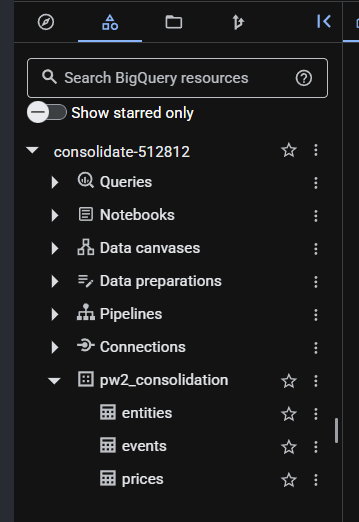

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [9]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [ ]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.